In [ ]:

logs = [
    "INFO: Server started successfully",
    "ERROR: Disk space is full",
    "WARNING: CPU usage is high",
    "INFO: Backup completed",
    "ERROR: Network connection failed",
    "WARNING: Memory usage is high",
    "INFO: User logged in",
    "ERROR: Disk space is full"

]

print("Total log entries:", len(logs))

for log in logs:
    print(log)


Total log entries: 8
INFO: Server started successfully
ERROR: Disk space is full
INFO: Backup completed
ERROR: Network connection failed
INFO: User logged in
ERROR: Disk space is full


In [ ]:

error_count = 0
warning_count = 0
info_count = 0

for log in logs:
    if "ERROR" in log:
        error_count += 1
    elif "WARNING" in log:
        warning_count += 1
    elif "INFO" in log:
        info_count += 1

print("Errors:", error_count)
print("Warnings:", warning_count)
print("Information:", info_count)


Errors: 3
Warnings: 2
Information: 3


In [ ]:

error_messages = []

for log in logs:
    if "ERROR" in log:
        message = log.split("ERROR: ")[1]
        error_messages.append(message)

error_summary = {}

for message in error_messages:
    error_summary[message] = error_summary.get(message, 0) + 1

for message, count in error_summary.items():
    print(message, "->", count)


Disk space is full -> 2
Network connection failed -> 1


In [ ]:

sample_logs = """INFO: Server started
ERROR: Disk space is full
WARNING: CPU usage is high
INFO: Backup completed
ERROR: Network connection failed
WARNING: Memory usage is high
ERROR: Disk space is full
INFO: Server check completed
ERROR: Printer connection failed
"""

with open("server.log", "w") as file:
    file.write(sample_logs)

print("Log file created successfully!")


Log file created successfully!


In [ ]:

with open("server.log", "r") as file:
    logs = file.readlines()

print("Total log entries:", len(logs))

for log in logs:
    print(log.strip())


Total log entries: 9
INFO: Server started
ERROR: Disk space is full
INFO: Backup completed
ERROR: Network connection failed
ERROR: Disk space is full
INFO: Server check completed
ERROR: Printer connection failed


In [ ]:

error_count = 0
warning_count = 0
info_count = 0

for log in logs:
    if "ERROR:" in log:
        error_count += 1
    elif "WARNING:" in log:
        warning_count += 1
    elif "INFO:" in log:
        info_count += 1

print("===== SERVER LOG REPORT =====")
print("Total entries:", len(logs))
print("Errors:", error_count)
print("Warnings:", warning_count)
print("Information:", info_count)


===== SERVER LOG REPORT =====
Total entries: 9
Errors: 4
Warnings: 2
Information: 3


In [ ]:

import pandas as pd

logs = [
    "INFO: Server started",
    "ERROR: Disk space is full",
    "WARNING: CPU usage is high",
    "INFO: Backup completed",
    "ERROR: Network connection failed",
    "WARNING: Memory usage is high",
    "ERROR: Disk space is full",
    "INFO: Server check completed",
]

rows = []

for log in logs:
    level, message = log.split(": ", 1)
    rows.append({
        "Level": level,
        "Message": message
    })

df = pd.DataFrame(rows)

df.head()


,Level,Message
0,INFO,Server started
1,ERROR,Disk space is full
2,WARNING,CPU usage is high
3,INFO,Backup completed
4,ERROR,Network connection failed


In [ ]:

summary = df["Level"].value_counts()

print("Total logs:", len(df))
print("Errors:", summary.get("ERROR", 0))
print("Warnings:", summary.get("WARNING", 0))
print("Information:", summary.get("INFO", 0))


Total logs: 8
Errors: 3
Warnings: 2
Information: 3


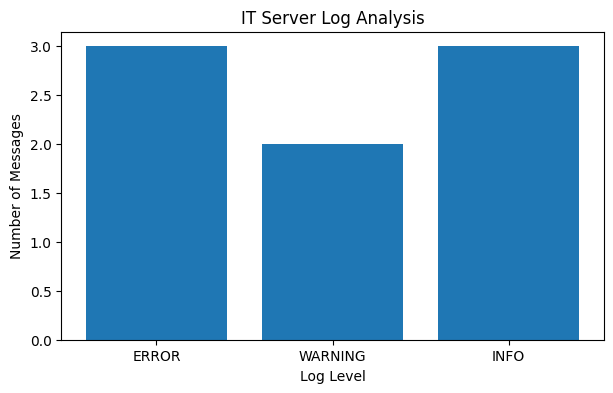

In [ ]:

import matplotlib.pyplot as plt

levels = ["ERROR", "WARNING", "INFO"]
counts = [
    summary.get("ERROR", 0),
    summary.get("WARNING", 0),
    summary.get("INFO", 0)
]

plt.figure(figsize=(7, 4))
plt.bar(levels, counts)
plt.title("IT Server Log Analysis")
plt.xlabel("Log Level")
plt.ylabel("Number of Messages")
plt.show()


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

logs = [
    "INFO: Server started",
    "ERROR: Disk space is full",
    "WARNING: CPU usage is high",
    "INFO: Backup completed",
    "ERROR: Network connection failed",
    "WARNING: Memory usage is high",
    "ERROR: Disk space is full",
    "INFO: Server check completed"
]

rows = []

for log in logs:
    level, message = log.split(": ", 1)
    rows.append({
        "Level": level,
        "Message": message
    })

df = pd.DataFrame(rows)

print(df)


     Level                    Message
0     INFO             Server started
1    ERROR         Disk space is full
2  WARNING          CPU usage is high
3     INFO           Backup completed
4    ERROR  Network connection failed
5  WARNING       Memory usage is high
6    ERROR         Disk space is full
7     INFO     Server check completed


In [ ]:

counts = df["Level"].value_counts()

print(counts)


Level
INFO       3
ERROR      3
WARNING    2
Name: count, dtype: int64


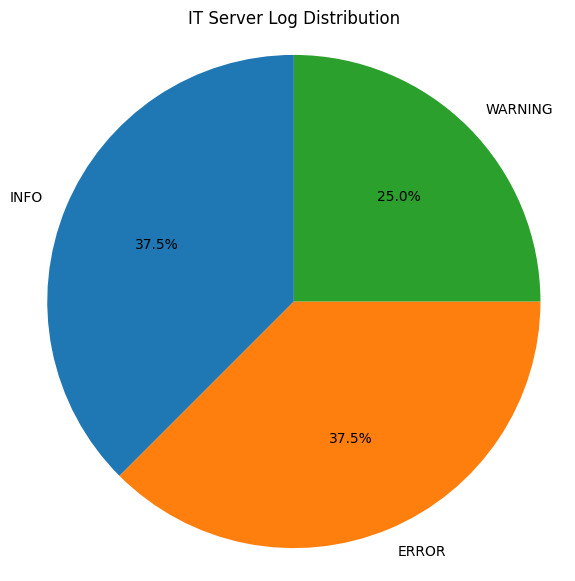

In [ ]:

plt.figure(figsize=(7, 7))

plt.pie(
    counts.values,
    labels=counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("IT Server Log Distribution")
plt.axis("equal")
plt.show()


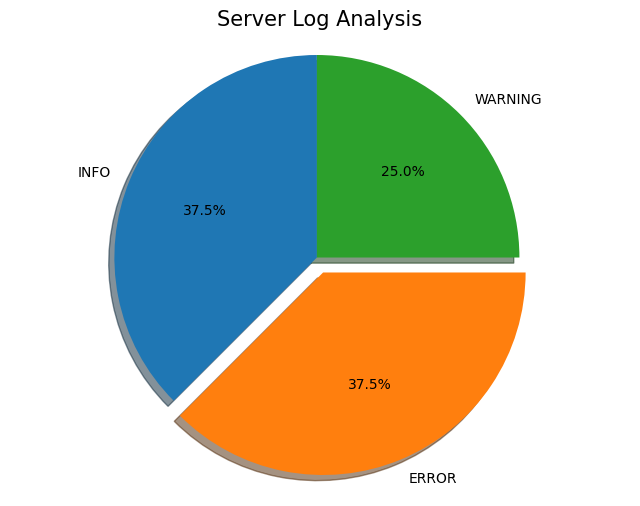

In [ ]:

counts = df["Level"].value_counts()

explode = [
    0.08 if level == "ERROR" else 0
    for level in counts.index
]

plt.figure(figsize=(8, 6))

plt.pie(
    counts.values,
    labels=counts.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=explode,
    shadow=True
)

plt.title("Server Log Analysis", fontsize=15)
plt.axis("equal")
plt.show()


In [ ]:

import pandas as pd

logs = [
    "INFO: Server started",
    "ERROR: Disk space is full",
    "WARNING: CPU usage is high",
    "INFO: Backup completed",
    "ERROR: Network connection failed",
    "WARNING: Memory usage is high",
    "ERROR: Disk space is full",
    "INFO: Server check completed",
]

rows = []

for log in logs:
    level, message = log.split(": ", 1)
    rows.append({
        "Level": level,
        "Message": message
    })

df = pd.DataFrame(rows)

print("All server logs:")
display(df)


All server logs:


,Level,Message
0,INFO,Server started
1,ERROR,Disk space is full
2,WARNING,CPU usage is high
3,INFO,Backup completed
4,ERROR,Network connection failed
5,WARNING,Memory usage is high
6,ERROR,Disk space is full
7,INFO,Server check completed


In [ ]:

# Select only error records
errors = df[df["Level"] == "ERROR"]

# Count repeated error messages
error_counts = errors["Message"].value_counts()

print("Repeated error analysis:")

for message, count in error_counts.items():
    if count > 1:
        print(f"ALERT: '{message}' occurred {count} times")
    else:
        print(f"NOTICE: '{message}' occurred once")


Repeated error analysis:
ALERT: 'Disk space is full' occurred 2 times
NOTICE: 'Network connection failed' occurred once


In [ ]:

error_total = len(errors)
warning_total = len(df[df["Level"] == "WARNING"])

if error_total >= 3:
    status = "HIGH RISK"
elif error_total >= 1:
    status = "ATTENTION REQUIRED"
else:
    status = "NORMAL"

print("===== IT LOG ANALYSIS REPORT =====")
print(f"Total logs: {len(df)}")
print(f"Errors: {error_total}")
print(f"Warnings: {warning_total}")
print(f"System status: {status}")


===== IT LOG ANALYSIS REPORT =====
Total logs: 8
Errors: 3
Warnings: 2
System status: HIGH RISK


In [ ]:

!pip -q install streamlit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 28.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 48.1 MB/s eta 0:00:00


In [ ]:

%%writefile app.py
import os
import joblib
import pandas as pd
import streamlit as st

# --------------------------------------------------
# 1. Application configuration
# --------------------------------------------------
st.set_page_config(
    page_title="IT Log Analyzer",
    page_icon="🖥️",
    layout="wide"
)

st.title("🖥️ IT Server Log Analyzer")
st.write(
    "Upload a server log file to analyze log levels, "
    "detect repeated errors, and predict categories using ML."
)

# --------------------------------------------------
# 2. Load the trained Machine Learning model
# --------------------------------------------------
MODEL_PATH = "/content/it_log_model.joblib"

@st.cache_resource
def load_model(path):
    return joblib.load(path)

if not os.path.exists(MODEL_PATH):
    st.error(
        "Model file not found: it_log_model.joblib. "
        "Save or upload the trained model into the same "
        "folder as app.py before starting the application."
    )
    st.stop()

try:
    model = load_model(MODEL_PATH)
except Exception as exc:
    st.error(f"Could not load the ML model: {exc}")
    st.stop()

# --------------------------------------------------
# 3. Troubleshooting recommendations
# --------------------------------------------------
recommendations = {
    "Disk space is full": (
        "Check disk usage, remove unnecessary files, "
        "and consider expanding storage after verification."
    ),
    "Network connection failed": (
        "Check connectivity, IP configuration, DNS, "
        "routing, and firewall rules."
    ),
    "CPU usage is high": (
        "Identify processes consuming CPU and review "
        "server performance."
    ),
    "Memory usage is high": (
        "Check memory utilization and identify processes "
        "with unusually high memory usage."
    ),
    "Backup failed": (
        "Review backup logs, destination storage, credentials, "
        "and network connectivity."
    )
}

# --------------------------------------------------
# 4. Upload a log file
# --------------------------------------------------
uploaded_file = st.file_uploader(
    "Choose a log file",
    type=["log", "txt"]
)

if uploaded_file is not None:
    try:
        content = uploaded_file.getvalue().decode(
            "utf-8", errors="replace"
        )

        lines = content.splitlines()
        rows = []

        for line in lines:
            line = line.strip()

            if not line:
                continue

            if ": " not in line:
                continue

            level, message = line.split(": ", 1)
            level = level.strip().upper()
            message = message.strip()

            if level and message:
                rows.append({
                    "Level": level,
                    "Message": message
                })

        df = pd.DataFrame(
            rows,
            columns=["Level", "Message"]
        )

        if df.empty:
            st.warning(
                "No valid log entries found. "
                "Expected format: ERROR: Disk space is full"
            )
            st.stop()

        # ------------------------------------------
        # 5. Machine Learning predictions
        # ------------------------------------------
        df["AI Prediction"] = model.predict(
            df["Message"].tolist()
        )

        # ------------------------------------------
        # 6. Summary metrics
        # ------------------------------------------
        errors = df[df["Level"] == "ERROR"]
        warnings = df[df["Level"] == "WARNING"]
        info_logs = df[df["Level"] == "INFO"]

        col1, col2, col3, col4 = st.columns(4)

        col1.metric("Total Logs", len(df))
        col2.metric("Errors", len(errors))
        col3.metric("Warnings", len(warnings))
        col4.metric("Info", len(info_logs))

        # ------------------------------------------
        # 7. System status based on existing log levels
        # ------------------------------------------
        st.subheader("System Status")

        if len(errors) >= 3:
            st.error("HIGH RISK: Multiple errors detected.")
        elif len(errors) >= 1:
            st.warning("ATTENTION REQUIRED: Errors detected.")
        else:
            st.success("NORMAL: No errors detected.")

        # ------------------------------------------
        # 8. Error frequency
        # ------------------------------------------
        st.subheader("Error Frequency")

        if not errors.empty:
            error_summary = (
                errors["Message"]
                .value_counts()
                .rename_axis("Error Message")
                .reset_index(name="Occurrences")
            )

            st.dataframe(
                error_summary,
                use_container_width=True
            )
        else:
            st.info("No errors found.")

        # ------------------------------------------
        # 9. Troubleshooting recommendations
        # ------------------------------------------
        st.subheader("Troubleshooting Recommendations")

        if not errors.empty:
            unique_errors = errors["Message"].unique()

            for message in unique_errors:
                st.markdown(f"**Error:** {message}")

                recommendation = recommendations.get(
                    message,
                    "No predefined recommendation. "
                    "Investigate the log details before taking action."
                )

                st.write(f"Suggested action: {recommendation}")
                st.divider()
        else:
            st.success("No errors require investigation.")

        # ------------------------------------------
        # 10. Display all logs and ML predictions
        # ------------------------------------------
        st.subheader("All Log Entries")
        st.dataframe(df, use_container_width=True)

        st.subheader("AI Prediction Summary")

        prediction_summary = (
            df["AI Prediction"]
            .value_counts()
            .rename_axis("Predicted Category")
            .reset_index(name="Count")
        )

        st.dataframe(
            prediction_summary,
            use_container_width=True
        )

        # ------------------------------------------
        # 11. Download analysis report
        # ------------------------------------------
        st.subheader("Download Analysis Report")

        csv_data = df.to_csv(index=False).encode("utf-8-sig")

        st.download_button(
            label="Download Analysis Report (CSV)",
            data=csv_data,
            file_name="it_log_analysis_report.csv",
            mime="text/csv"
        )

    except Exception as exc:
        st.error(f"An error occurred while analyzing the file: {exc}")


Overwriting app.py


In [ ]:

%%writefile sample.log
INFO: Server started
ERROR: Disk space is full
WARNING: CPU usage is high
INFO: Backup completed
ERROR: Network connection failed
WARNING: Memory usage is high
ERROR: Disk space is full
INFO: Server check completed


Overwriting sample.log


In [ ]:

import streamlit as st
print("Streamlit version:", st.__version__)
print("Application file created:", __import__("os").path.exists("app.py"))
print("Sample log file created:", __import__("os").path.exists("sample.log"))


In [ ]:

!pip -q install pyngrok


In [ ]:

from pyngrok import ngrok
import subprocess
import time

# Add your ngrok token here
ngrok.set_auth_token("3L3064hLlRH9OmDrwOKXq85GSqI_5RPU3D9n2f6mRbAk9TnEA")

# Start Streamlit
process = subprocess.Popen([
    "streamlit", "run", "app.py",
    "--server.port", "8501",
    "--server.address", "0.0.0.0",
    "--server.headless", "true"
])

# Create a temporary public URL
public_url = ngrok.connect(8501)
print("Your IT Log Analyzer URL:")
print(public_url)


In [ ]:

training_messages = [
    "Disk space is full",
    "Not enough disk space",
    "Storage capacity exceeded",
    "Network connection failed",
    "Cannot connect to network",
    "Network unreachable",
    "CPU usage is high",
    "High processor utilization",
    "Memory usage is high",
    "RAM usage exceeded",
    "Server started successfully",
    "Backup completed successfully",
    "System check completed",
    "User logged in successfully",
    "Scheduled task completed"
]

training_labels = [
    "ERROR",
    "ERROR",
    "ERROR",
    "ERROR",
    "ERROR",
    "ERROR",
    "WARNING",
    "WARNING",
    "WARNING",
    "WARNING",
    "INFO",
    "INFO",
    "INFO",
    "INFO",
    "INFO"
]

print("Training examples:", len(training_messages))
print("Labels:", len(training_labels))


Training examples: 15
Labels: 15


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("vectorizer", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(training_messages, training_labels)

print("AI model trained successfully!")
print("Number of training messages:", len(training_messages))
print("Number of training labels:", len(training_labels))
print("Available categories:", model.classes_)


AI model trained successfully!
Number of training messages: 15
Number of training labels: 15
Available categories: ['ERROR' 'INFO' 'WARNING']


In [ ]:

new_messages = [
    "Disk is almost full",
    "The server CPU is overloaded",
    "Backup completed successfully",
    "Network unreachable"
]

predictions = model.predict(new_messages)

for message, prediction in zip(new_messages, predictions):
    print(f"Message: {message}")
    print(f"Predicted category: {prediction}")
    print("-" * 40)


Message: Disk is almost full
Predicted category: ERROR
----------------------------------------
Message: The server CPU is overloaded
Predicted category: ERROR
----------------------------------------
Message: Backup completed successfully
Predicted category: INFO
----------------------------------------
Message: Network unreachable
Predicted category: ERROR
----------------------------------------


In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    training_messages,
    training_labels,
    test_size=0.33,
    random_state=42,
    stratify=training_labels
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))


Training examples: 10
Testing examples: 5


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score, classification_report

evaluation_model = Pipeline([
    ("vectorizer", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

evaluation_model.fit(X_train, y_train)

test_predictions = evaluation_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, test_predictions))
print()
print(classification_report(
    y_test,
    test_predictions,
    zero_division=0
))


Accuracy: 1.0

              precision    recall  f1-score   support

       ERROR       1.00      1.00      1.00         2
        INFO       1.00      1.00      1.00         2
     WARNING       1.00      1.00      1.00         1

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5



In [ ]:

for message, actual, predicted in zip(
    X_test, y_test, test_predictions
):
    result = "CORRECT" if actual == predicted else "INCORRECT"

    print("Message:", message)
    print("Actual:", actual)
    print("Predicted:", predicted)
    print("Result:", result)
    print("-" * 35)


Message: Memory usage is high
Actual: WARNING
Predicted: WARNING
Result: CORRECT
-----------------------------------
Message: Server started successfully
Actual: INFO
Predicted: INFO
Result: CORRECT
-----------------------------------
Message: Cannot connect to network
Actual: ERROR
Predicted: ERROR
Result: CORRECT
-----------------------------------
Message: Scheduled task completed
Actual: INFO
Predicted: INFO
Result: CORRECT
-----------------------------------
Message: Network connection failed
Actual: ERROR
Predicted: ERROR
Result: CORRECT
-----------------------------------


In [ ]:

import joblib
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Train the final model using all available training examples
final_model = Pipeline([
    ("vectorizer", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

final_model.fit(training_messages, training_labels)

# Save the trained model
joblib.dump(final_model, "it_log_model.joblib")

print("Model saved successfully!")


Model saved successfully!


In [ ]:

import os

model_path = "it_log_model.joblib"

print("Model file exists:", os.path.exists(model_path))
print("Model file size:", os.path.getsize(model_path), "bytes")


Model file exists: True
Model file size: 3169 bytes


In [ ]:

!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true




2026-10-23 07:54:41.917 Port 8501 is not available


In [ ]:

training_data = [
    # ERROR - 20 examples
    ("Disk space is full", "ERROR"),
    ("Not enough disk space", "ERROR"),
    ("Storage capacity exceeded", "ERROR"),
    ("Network connection failed", "ERROR"),
    ("Network unreachable", "ERROR"),
    ("DNS resolution failed", "ERROR"),
    ("Server failed to start", "ERROR"),
    ("Windows service stopped unexpectedly", "ERROR"),
    ("Backup failed", "ERROR"),
    ("Backup destination unavailable", "ERROR"),
    ("Authentication failed", "ERROR"),
    ("Access denied to shared folder", "ERROR"),
    ("File server is unavailable", "ERROR"),
    ("Database connection failed", "ERROR"),
    ("Virtual machine failed to boot", "ERROR"),
    ("ESXi datastore is full", "ERROR"),
    ("Disk read write error", "ERROR"),
    ("Printer connection failed", "ERROR"),
    ("IP address conflict detected", "ERROR"),
    ("Critical system error occurred", "ERROR"),

    # WARNING - 20 examples
    ("CPU usage is high", "WARNING"),
    ("Memory usage is high", "WARNING"),
    ("Disk space is running low", "WARNING"),
    ("Network latency is elevated", "WARNING"),
    ("Backup is taking longer than usual", "WARNING"),
    ("Multiple failed login attempts", "WARNING"),
    ("Server temperature is elevated", "WARNING"),
    ("Virtual machine memory pressure detected", "WARNING"),
    ("Network bandwidth is almost exhausted", "WARNING"),
    ("Certificate will expire soon", "WARNING"),
    ("Printer toner is low", "WARNING"),
    ("Storage utilization is above threshold", "WARNING"),
    ("Service restart recommended", "WARNING"),
    ("Packet loss detected", "WARNING"),
    ("High number of active connections", "WARNING"),
    ("Backup storage is nearly full", "WARNING"),
    ("CPU temperature is elevated", "WARNING"),
    ("Disk response time is high", "WARNING"),
    ("Repeated login failures detected", "WARNING"),
    ("System resource usage is elevated", "WARNING"),

    # INFO - 20 examples
    ("Server started successfully", "INFO"),
    ("Backup completed successfully", "INFO"),
    ("System check completed", "INFO"),
    ("User logged in successfully", "INFO"),
    ("Scheduled task completed", "INFO"),
    ("Network connection established", "INFO"),
    ("Windows service started", "INFO"),
    ("Virtual machine started successfully", "INFO"),
    ("Disk health check completed", "INFO"),
    ("DNS lookup completed", "INFO"),
    ("Printer job completed", "INFO"),
    ("Configuration saved successfully", "INFO"),
    ("Security update installed", "INFO"),
    ("File copied successfully", "INFO"),
    ("Network adapter initialized", "INFO"),
    ("Backup schedule registered", "INFO"),
    ("User logged out successfully", "INFO"),
    ("System maintenance completed", "INFO"),
    ("Service configuration loaded", "INFO"),
    ("Server shutdown completed normally", "INFO"),
]

training_messages = [message for message, label in training_data]
training_labels = [label for message, label in training_data]

import pandas as pd

training_df = pd.DataFrame(
    training_data,
    columns=["Message", "Level"]
)

print("Total examples:", len(training_df))
print("\nExamples per category:")
print(training_df["Level"].value_counts())

display(training_df.head(10))


Total examples: 60

Examples per category:
Level
ERROR      20
WARNING    20
INFO       20
Name: count, dtype: int64


,Message,Level
0,Disk space is full,ERROR
1,Not enough disk space,ERROR
2,Storage capacity exceeded,ERROR
3,Network connection failed,ERROR
4,Network unreachable,ERROR
5,DNS resolution failed,ERROR
6,Server failed to start,ERROR
7,Windows service stopped unexpectedly,ERROR
8,Backup failed,ERROR
9,Backup destination unavailable,ERROR


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
import joblib

final_model = Pipeline([
    ("vectorizer", TfidfVectorizer(ngram_range=(1, 2))),
    ("classifier", LogisticRegression(max_iter=1000))
])

final_model.fit(training_messages, training_labels)

joblib.dump(final_model, "it_log_model.joblib")

print("New model trained and saved successfully!")


In [ ]:
import pandas as pd

# Inspect the training dataset
df_training = pd.DataFrame({
    "Message": training_messages,
    "Label": training_labels
})

print("Total training examples:", len(df_training))
print("\nLabel distribution:")
print(df_training["Label"].value_counts())

# Normalize text to detect duplicate messages
df_training["Normalized_Message"] = (
    df_training["Message"]
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

print(
    "\nUnique normalized messages:",
    df_training["Normalized_Message"].nunique()
)

print(
    "Duplicate normalized rows:",
    df_training.duplicated(
        subset=["Normalized_Message", "Label"]
    ).sum()
)

# Find identical messages with conflicting labels
label_counts = df_training.groupby(
    "Normalized_Message"
)["Label"].nunique()

print(
    "Messages with conflicting labels:",
    (label_counts > 1).sum()
)

In [ ]:

test_messages = [
    "The ESXi datastore is full",
    "The server CPU usage is high",
    "Windows service started",
    "Backup destination unavailable",
    "Network connection established",
    "Disk space is running low"
]

predictions = final_model.predict(test_messages)

for message, prediction in zip(test_messages, predictions):
    print(f"Message: {message}")
    print(f"Predicted category: {prediction}")
    print("-" * 40)


Message: The ESXi datastore is full
Predicted category: ERROR
----------------------------------------
Message: The server CPU usage is high
Predicted category: WARNING
----------------------------------------
Message: Windows service started
Predicted category: INFO
----------------------------------------
Message: Backup destination unavailable
Predicted category: ERROR
----------------------------------------
Message: Network connection established
Predicted category: INFO
----------------------------------------
Message: Disk space is running low
Predicted category: WARNING
----------------------------------------


In [ ]:
print("Total examples:", len(training_messages))
print("\nExamples per category:")

import pandas as pd

print(pd.Series(training_labels).value_counts())

Total examples: 60

Examples per category:
ERROR      20
WARNING    20
INFO       20
Name: count, dtype: int64


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    training_messages,
    training_labels,
    test_size=0.20,
    random_state=42,
    stratify=training_labels
)

# Build a fresh model for evaluation
evaluation_model = Pipeline([
    ("vectorizer", TfidfVectorizer(ngram_range=(1, 2))),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train only on the training portion
evaluation_model.fit(X_train, y_train)

# Predict categories for unseen test messages
y_pred = evaluation_model.predict(X_test)

# Evaluate performance
print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))
print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 3))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=["ERROR", "WARNING", "INFO"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred,
    labels=["ERROR", "WARNING", "INFO"]
))


Training messages: 48
Testing messages: 12

Accuracy: 0.917

Classification Report:
              precision    recall  f1-score   support

       ERROR       1.00      0.75      0.86         4
     WARNING       1.00      1.00      1.00         4
        INFO       0.80      1.00      0.89         4

    accuracy                           0.92        12
   macro avg       0.93      0.92      0.92        12
weighted avg       0.93      0.92      0.92        12

Confusion Matrix:
[[3 0 1]
 [0 4 0]
 [0 0 4]]


In [ ]:

# Compare actual labels with predicted labels

results_df = pd.DataFrame({
    "Message": X_test,
    "Actual": y_test,
    "Predicted": y_pred
})

print("All test predictions:")
display(results_df)

print("\nIncorrect predictions:")
display(
    results_df[results_df["Actual"] != results_df["Predicted"]]
)


All test predictions:


,Message,Actual,Predicted
0,Virtual machine failed to boot,ERROR,ERROR
1,Disk response time is high,WARNING,WARNING
2,Backup completed successfully,INFO,INFO
3,Configuration saved successfully,INFO,INFO
4,Network latency is elevated,WARNING,WARNING
5,Server failed to start,ERROR,ERROR
6,Network bandwidth is almost exhausted,WARNING,WARNING
7,Authentication failed,ERROR,ERROR
8,Server started successfully,INFO,INFO
9,System maintenance completed,INFO,INFO



Incorrect predictions:


,Message,Actual,Predicted
11,Windows service stopped unexpectedly,ERROR,INFO


In [ ]:

# Add more examples to improve service-related classification

extra_training_data = [
    ("Windows service stopped unexpectedly", "ERROR"),
    ("Critical Windows service failed", "ERROR"),
    ("Server service crashed unexpectedly", "ERROR"),
    ("Required system service failed to start", "ERROR"),
    ("Windows service is not responding", "ERROR"),
    ("Windows service started successfully", "INFO"),
    ("System service is running normally", "INFO"),
    ("Windows service status checked successfully", "INFO"),
    ("Service started and is operating normally", "INFO"),
    ("System service initialization completed", "INFO"),
]

training_data.extend(extra_training_data)

training_messages = [message for message, label in training_data]
training_labels = [label for message, label in training_data]

print("Updated training examples:", len(training_messages))
print(pd.Series(training_labels).value_counts())


Updated training examples: 70
ERROR      25
INFO       25
WARNING    20
Name: count, dtype: int64


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

X_train, X_test, y_train, y_test = train_test_split(
    training_messages,
    training_labels,
    test_size=0.20,
    random_state=42,
    stratify=training_labels
)

evaluation_model = Pipeline([
    ("vectorizer", TfidfVectorizer(ngram_range=(1, 2))),
    ("classifier", LogisticRegression(max_iter=1000))
])

evaluation_model.fit(X_train, y_train)
y_pred = evaluation_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred, zero_division=0))

results_df = pd.DataFrame({
    "Message": X_test,
    "Actual": y_test,
    "Predicted": y_pred
})

print("Incorrect predictions:")
display(results_df[results_df["Actual"] != results_df["Predicted"]])


Accuracy: 0.929
              precision    recall  f1-score   support

       ERROR       0.83      1.00      0.91         5
        INFO       1.00      0.80      0.89         5
     WARNING       1.00      1.00      1.00         4

    accuracy                           0.93        14
   macro avg       0.94      0.93      0.93        14
weighted avg       0.94      0.93      0.93        14

Incorrect predictions:


,Message,Actual,Predicted
3,System service is running normally,INFO,ERROR


In [ ]:

extra_service_data = [
    ("System service is running normally", "INFO"),
    ("Windows service is operating normally", "INFO"),
    ("All required services are running", "INFO"),
    ("Service health check completed successfully", "INFO"),
    ("System services are functioning correctly", "INFO"),
    ("Windows service stopped unexpectedly", "ERROR"),
    ("Critical system service crashed", "ERROR"),
    ("Required service failed to start", "ERROR"),
    ("System service terminated unexpectedly", "ERROR"),
    ("Service startup failed with an error", "ERROR"),
]

training_data.extend(extra_service_data)

training_messages = [message for message, label in training_data]
training_labels = [label for message, label in training_data]

print("Total examples:", len(training_messages))
print("\nExamples per category:")
print(pd.Series(training_labels).value_counts())


Total examples: 80

Examples per category:
ERROR      30
INFO       30
WARNING    20
Name: count, dtype: int64


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    training_messages,
    training_labels,
    test_size=0.20,
    random_state=42,
    stratify=training_labels
)

evaluation_model = Pipeline([
    ("vectorizer", TfidfVectorizer(ngram_range=(1, 2))),
    ("classifier", LogisticRegression(max_iter=1000))
])

evaluation_model.fit(X_train, y_train)
y_pred = evaluation_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred, zero_division=0))

results_df = pd.DataFrame({
    "Message": X_test,
    "Actual": y_test,
    "Predicted": y_pred
})

print("Incorrect predictions:")
display(results_df[results_df["Actual"] != results_df["Predicted"]])


Accuracy: 0.812
              precision    recall  f1-score   support

       ERROR       0.75      1.00      0.86         6
        INFO       0.80      0.67      0.73         6
     WARNING       1.00      0.75      0.86         4

    accuracy                           0.81        16
   macro avg       0.85      0.81      0.81        16
weighted avg       0.83      0.81      0.81        16

Incorrect predictions:


,Message,Actual,Predicted
1,Network adapter initialized,INFO,ERROR
2,Backup schedule registered,INFO,ERROR
14,Virtual machine memory pressure detected,WARNING,INFO


In [ ]:

correction_data = [
    # INFO: normal operations
    ("Network adapter initialized", "INFO"),
    ("Backup schedule registered", "INFO"),
    ("Network adapter initialized successfully", "INFO"),
    ("Backup schedule registered successfully", "INFO"),
    ("Virtual machine started successfully", "INFO"),
    ("Memory health check completed", "INFO"),

    # WARNING: resource pressure
    ("Virtual machine memory pressure detected", "WARNING"),
    ("Virtual machine memory usage is elevated", "WARNING"),
    ("Server memory pressure is increasing", "WARNING"),
    ("High memory utilization warning", "WARNING"),
    ("Virtual machine is low on available memory", "WARNING"),

    # ERROR: clear failures
    ("Network adapter initialization failed", "ERROR"),
    ("Backup schedule registration failed", "ERROR"),
    ("Virtual machine failed to start", "ERROR"),
    ("Memory allocation failed", "ERROR"),
    ("Network adapter is not responding", "ERROR"),
]

training_data.extend(correction_data)

training_messages = [message for message, label in training_data]
training_labels = [label for message, label in training_data]

print("Total examples:", len(training_messages))
print(pd.Series(training_labels).value_counts())


Total examples: 96
INFO       36
ERROR      35
WARNING    25
Name: count, dtype: int64


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    training_messages,
    training_labels,
    test_size=0.20,
    random_state=42,
    stratify=training_labels
)

evaluation_model = Pipeline([
    ("vectorizer", TfidfVectorizer(ngram_range=(1, 2))),
    ("classifier", LogisticRegression(max_iter=1000))
])

evaluation_model.fit(X_train, y_train)
y_pred = evaluation_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred, zero_division=0))

results_df = pd.DataFrame({
    "Message": X_test,
    "Actual": y_test,
    "Predicted": y_pred
})

print("Incorrect predictions:")
display(results_df[results_df["Actual"] != results_df["Predicted"]])


Accuracy: 0.95
              precision    recall  f1-score   support

       ERROR       0.88      1.00      0.93         7
        INFO       1.00      1.00      1.00         8
     WARNING       1.00      0.80      0.89         5

    accuracy                           0.95        20
   macro avg       0.96      0.93      0.94        20
weighted avg       0.96      0.95      0.95        20

Incorrect predictions:


,Message,Actual,Predicted
1,Certificate will expire soon,WARNING,ERROR


In [ ]:

certificate_test_messages = [
    "Certificate will expire soon",
    "SSL certificate expires in 7 days",
    "TLS certificate expiration warning",
    "SSL certificate has expired",
    "Certificate validation failed",
    "New security certificate installed successfully",
    "Certificate renewal completed successfully",
    "Certificate expiration alert generated"
]

certificate_predictions = evaluation_model.predict(
    certificate_test_messages
)

certificate_results = pd.DataFrame({
    "Message": certificate_test_messages,
    "Predicted Category": certificate_predictions
})

display(certificate_results)


,Message,Predicted Category
0,Certificate will expire soon,ERROR
1,SSL certificate expires in 7 days,ERROR
2,TLS certificate expiration warning,ERROR
3,SSL certificate has expired,ERROR
4,Certificate validation failed,ERROR
5,New security certificate installed successfully,INFO
6,Certificate renewal completed successfully,INFO
7,Certificate expiration alert generated,ERROR


In [ ]:

certificate_training_data = [
    # WARNING: certificate approaching expiration
    ("Certificate will expire soon", "WARNING"),
    ("SSL certificate expires in 7 days", "WARNING"),
    ("TLS certificate expiration warning", "WARNING"),
    ("Certificate expires in 30 days", "WARNING"),
    ("Certificate renewal is required soon", "WARNING"),
    ("Certificate expiration alert generated", "WARNING"),

    # ERROR: actual failures
    ("SSL certificate has expired", "ERROR"),
    ("Certificate validation failed", "ERROR"),
    ("SSL certificate verification failed", "ERROR"),
    ("TLS handshake failed due to invalid certificate", "ERROR"),
    ("Certificate is revoked", "ERROR"),
    ("Secure connection failed due to certificate error", "ERROR"),

    # INFO: successful operations
    ("New security certificate installed successfully", "INFO"),
    ("Certificate renewal completed successfully", "INFO"),
    ("Certificate validation completed successfully", "INFO"),
    ("SSL certificate configuration saved successfully", "INFO"),
    ("New TLS certificate loaded successfully", "INFO"),
    ("Certificate monitoring service started successfully", "INFO"),
]

training_data.extend(certificate_training_data)

training_messages = [message for message, label in training_data]
training_labels = [label for message, label in training_data]

print("Total examples:", len(training_messages))
print("\nExamples per category:")
print(pd.Series(training_labels).value_counts())


Total examples: 114

Examples per category:
INFO       42
ERROR      41
WARNING    31
Name: count, dtype: int64


In [ ]:

evaluation_model = Pipeline([
    ("vectorizer", TfidfVectorizer(ngram_range=(1, 2))),
    ("classifier", LogisticRegression(max_iter=1000))
])

evaluation_model.fit(training_messages, training_labels)

print("Model retrained successfully.")


Model retrained successfully.


In [ ]:

certificate_predictions = evaluation_model.predict(
    certificate_test_messages
)

certificate_results = pd.DataFrame({
    "Message": certificate_test_messages,
    "Predicted Category": certificate_predictions
})

display(certificate_results)


,Message,Predicted Category
0,Certificate will expire soon,WARNING
1,SSL certificate expires in 7 days,WARNING
2,TLS certificate expiration warning,WARNING
3,SSL certificate has expired,ERROR
4,Certificate validation failed,ERROR
5,New security certificate installed successfully,INFO
6,Certificate renewal completed successfully,INFO
7,Certificate expiration alert generated,WARNING


In [ ]:

unseen_messages = [
    "Our HTTPS certificate needs renewal within 10 days",
    "The web server certificate is no longer valid",
    "Certificate chain verification returned an error",
    "Security certificate renewal finished without errors",
    "TLS certificate is approaching its expiration date",
    "The application could not establish a secure connection",
    "Certificate configuration loaded successfully",
    "The certificate authority revoked this certificate",
    "A certificate expiration notification was raised",
    "HTTPS service started successfully after certificate renewal"
]

unseen_predictions = evaluation_model.predict(unseen_messages)

unseen_results = pd.DataFrame({
    "Message": unseen_messages,
    "Predicted Category": unseen_predictions
})

display(unseen_results)


,Message,Predicted Category
0,Our HTTPS certificate needs renewal within 10 ...,WARNING
1,The web server certificate is no longer valid,WARNING
2,Certificate chain verification returned an error,ERROR
3,Security certificate renewal finished without ...,INFO
4,TLS certificate is approaching its expiration ...,WARNING
5,The application could not establish a secure c...,ERROR
6,Certificate configuration loaded successfully,INFO
7,The certificate authority revoked this certifi...,ERROR
8,A certificate expiration notification was raised,WARNING
9,HTTPS service started successfully after certi...,INFO


In [ ]:

validity_training_data = [
    ("The web server certificate is no longer valid", "ERROR"),
    ("The server certificate is invalid", "ERROR"),
    ("The HTTPS certificate is no longer trusted", "ERROR"),
    ("The certificate validity check failed", "ERROR"),
    ("The website certificate has become invalid", "ERROR"),
    ("The certificate is approaching its expiration date", "WARNING"),
    ("The HTTPS certificate expires next week", "WARNING"),
    ("The certificate remains valid and was loaded successfully", "INFO"),
    ("The certificate renewal completed successfully", "INFO"),
]

training_data.extend(validity_training_data)

training_messages = [message for message, label in training_data]
training_labels = [label for message, label in training_data]

print("Total training examples:", len(training_messages))
print(pd.Series(training_labels).value_counts())


Total training examples: 123
ERROR      46
INFO       44
WARNING    33
Name: count, dtype: int64


In [ ]:

evaluation_model = Pipeline([
    ("vectorizer", TfidfVectorizer(ngram_range=(1, 2))),
    ("classifier", LogisticRegression(max_iter=1000))
])

evaluation_model.fit(training_messages, training_labels)

import joblib

joblib.dump(evaluation_model, "it_log_model.joblib")

print("Updated model trained and saved successfully!")


Updated model trained and saved successfully!


In [ ]:

final_check_messages = [
    "The web server certificate is no longer valid",
    "The HTTPS certificate expires next week",
    "Certificate renewal completed successfully",
    "Certificate chain verification returned an error",
    "Windows service stopped unexpectedly",
    "Virtual machine memory pressure detected"
]

final_check_predictions = evaluation_model.predict(final_check_messages)

for message, prediction in zip(
    final_check_messages,
    final_check_predictions
):
    print(f"{prediction:8} | {message}")


ERROR    | The web server certificate is no longer valid
WARNING  | The HTTPS certificate expires next week
INFO     | Certificate renewal completed successfully
ERROR    | Certificate chain verification returned an error
ERROR    | Windows service stopped unexpectedly
WARNING  | Virtual machine memory pressure detected


In [ ]:

import os
import joblib

model_path = "it_log_model.joblib"

print("Model file exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print("Model file size:", os.path.getsize(model_path), "bytes")
    loaded_model = joblib.load(model_path)
    print("Model loaded successfully!")
else:
    print("Model file is missing.")


Model file exists: True
Model file size: 23412 bytes
Model loaded successfully!


In [ ]:

%pip install streamlit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 38.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 57.5 MB/s eta 0:00:00


In [ ]:

!python -m streamlit run app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true


Usage: streamlit run [OPTIONS] [TARGET] [ARGS]...
Try 'streamlit run --help' for help.

Error: Invalid value: File does not exist: app.py


In [ ]:

import os

print("Current folder:", os.getcwd())
print("\nFiles in current folder:")

for filename in os.listdir():
    print(filename)


Current folder: /content

Files in current folder:
.config
it_log_model.joblib
sample_data


In [ ]:

%%writefile app.py
import os
import joblib
import pandas as pd
import streamlit as st

st.set_page_config(
    page_title="IT Log Analyzer",
    page_icon="🖥️",
    layout="wide"
)

st.title("🖥️ IT Server Log Analyzer")
st.write(
    "Upload a server log file to analyze log levels, "
    "detect repeated errors, and predict categories using ML."
)

MODEL_PATH = "it_log_model.joblib"

if not os.path.exists(MODEL_PATH):
    st.error("Model file not found: it_log_model.joblib")
    st.stop()

@st.cache_resource
def load_model(path):
    return joblib.load(path)

try:
    model = load_model(MODEL_PATH)
except Exception as exc:
    st.error(f"Could not load the ML model: {exc}")
    st.stop()

recommendations = {
    "Disk space is full":
        "Check disk usage and consider expanding storage after verification.",
    "Network connection failed":
        "Check connectivity, IP configuration, DNS, routing, and firewall rules.",
    "CPU usage is high":
        "Identify processes consuming CPU and review server performance.",
    "Memory usage is high":
        "Check memory utilization and identify processes using excessive memory.",
    "Backup failed":
        "Review backup logs, destination storage, credentials, and connectivity."
}

uploaded_file = st.file_uploader(
    "Choose a log file",
    type=["log", "txt"]
)

if uploaded_file is not None:
    try:
        content = uploaded_file.getvalue().decode(
            "utf-8", errors="replace"
        )

        rows = []

        for line in content.splitlines():
            line = line.strip()

            if not line or ": " not in line:
                continue

            level, message = line.split(": ", 1)
            level = level.strip().upper()
            message = message.strip()

            if level and message:
                rows.append({
                    "Level": level,
                    "Message": message
                })

        df = pd.DataFrame(rows, columns=["Level", "Message"])

        if df.empty:
            st.warning(
                "No valid log entries found. "
                "Expected format: ERROR: Disk space is full"
            )
            st.stop()

        df["AI Prediction"] = model.predict(
            df["Message"].tolist()
        )

        errors = df[df["Level"] == "ERROR"]
        warnings = df[df["Level"] == "WARNING"]
        info_logs = df[df["Level"] == "INFO"]

        col1, col2, col3, col4 = st.columns(4)
        col1.metric("Total Logs", len(df))
        col2.metric("Errors", len(errors))
        col3.metric("Warnings", len(warnings))
        col4.metric("Info", len(info_logs))

        st.subheader("System Status")

        if len(errors) >= 3:
            st.error("HIGH RISK: Multiple errors detected.")
        elif len(errors) >= 1:
            st.warning("ATTENTION REQUIRED: Errors detected.")
        else:
            st.success("NORMAL: No errors detected.")

        st.subheader("Error Frequency")

        if not errors.empty:
            error_summary = (
                errors["Message"]
                .value_counts()
                .rename_axis("Error Message")
                .reset_index(name="Occurrences")
            )
            st.dataframe(error_summary, use_container_width=True)
        else:
            st.info("No errors found.")

        st.subheader("Troubleshooting Recommendations")

        if not errors.empty:
            for message in errors["Message"].unique():
                st.markdown(f"**Error:** {message}")
                recommendation = recommendations.get(
                    message,
                    "Investigate the log details before taking action."
                )
                st.write(f"Suggested action: {recommendation}")
                st.divider()
        else:
            st.success("No errors require investigation.")

        st.subheader("All Log Entries")
        st.dataframe(df, use_container_width=True)

        st.subheader("AI Prediction Summary")

        prediction_summary = (
            df["AI Prediction"]
            .value_counts()
            .rename_axis("Predicted Category")
            .reset_index(name="Count")
        )

        st.dataframe(prediction_summary, use_container_width=True)

        st.subheader("Download Analysis Report")

        csv_data = df.to_csv(index=False).encode("utf-8-sig")

        st.download_button(
            label="Download Analysis Report (CSV)",
            data=csv_data,
            file_name="it_log_analysis_report.csv",
            mime="text/csv"
        )

    except Exception as exc:
        st.error(f"An error occurred while analyzing the file: {exc}")


Writing app.py


In [ ]:
import os

print("app.py exists:", os.path.exists("app.py"))
print("Model exists:", os.path.exists("it_log_model.joblib"))

app.py exists: True
Model exists: True


In [ ]:

!python -m streamlit run app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true




2026-10-23 05:50:04.645 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.83.63.113:8501

  Stopping...
  Stopping...


In [ ]:

from pyngrok import ngrok

ngrok.kill()

public_url = ngrok.connect(8501)
print("Your IT Log Analyzer URL:", public_url)


ModuleNotFoundError: No module named 'pyngrok'

In [ ]:

from pyngrok import ngrok

print(ngrok.get_tunnels())


In [ ]:

!curl -I --max-time 5 http://127.0.0.1:8501


curl: (7) Failed to connect to 127.0.0.1 port 8501 after 0 ms: Couldn't connect to server


In [ ]:

print("Colab is working")


Colab is working


In [ ]:

import socket

sock = socket.socket()
sock.settimeout(3)

try:
    sock.connect(("127.0.0.1", 8501))
    print("SUCCESS: Streamlit port 8501 is responding.")
except Exception as e:
    print("Streamlit connection failed:", repr(e))
finally:
    sock.close()


Streamlit connection failed: ConnectionRefusedError(111, 'Connection refused')


In [ ]:

import subprocess
import os

log_file = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        "python", "-m", "streamlit", "run", "/content/app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

print("Streamlit started in background.")
print("Process ID:", process.pid)


Streamlit started in background.
Process ID: 19499


In [ ]:

import time
import socket

time.sleep(3)

sock = socket.socket()
sock.settimeout(3)

try:
    sock.connect(("127.0.0.1", 8501))
    print("SUCCESS: Streamlit is running.")
except Exception as e:
    print("Connection failed:", e)
finally:
    sock.close()


SUCCESS: Streamlit is running.


In [ ]:
from pyngrok import ngrok

public_url = ngrok.connect(8501)
print("Your public app URL:", public_url)

ModuleNotFoundError: No module named 'pyngrok'

In [ ]:
!pip install -q pyngrok

In [ ]:
from pyngrok import ngrok

public_url = ngrok.connect(8501)
print("Your public app URL:", public_url)

ERROR:pyngrok.process.ngrok:t=2026-10-23T05:57:13+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"
ERROR:pyngrok.process.ngrok:t=2026-10-23T05:57:13+0000 lvl=eror msg="session closing" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"
CRITICAL:pyngrok.process.ngrok:t=2026-10-23T05:57:13+0000 lvl=crit msg="command failed" err="authentication failed: This ngrok session is not authenticated. ngrok requi

PyngrokNgrokError: The ngrok process errored on start: authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n.

In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token("3L3064hLlRH9OmDrwOKXq85GSqI_5RPU3D9n2f6mRbAk9TnEA")

public_url = ngrok.connect(8501)
print("Your public app URL:", public_url)

Your public app URL: NgrokTunnel: "https://strongman-throat-outdoors.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
%%writefile /content/test_ai.log
ERROR: Disk space is full
ERROR: Network connection failed
WARNING: CPU usage is high
INFO: Backup completed successfully
INFO: User login successful
ERROR: Backup failed
WARNING: Memory usage is high
INFO: Certificate renewal completed successfully

Writing /content/test_ai.log


In [ ]:
from google.colab import files
files.download('/content/test_ai.log')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%%writefile /content/test_ai_2.log
ERROR: Database connection timeout
WARNING: Server response time is slow
INFO: Scheduled maintenance completed
ERROR: Authentication service unavailable
WARNING: Certificate expires in three days
INFO: New user account created

Writing /content/test_ai_2.log


In [ ]:
from google.colab import files
files.download('/content/test_ai_2.log')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

X_train, X_test, y_train, y_test = train_test_split(
    training_messages,
    training_labels,
    test_size=0.20,
    random_state=42,
    stratify=training_labels
)

evaluation_model = Pipeline([
    ("vectorizer", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

evaluation_model.fit(X_train, y_train)

y_pred = evaluation_model.predict(X_test)

print("Test messages:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Test messages: 25
Accuracy: 88.0 %

Classification Report:
              precision    recall  f1-score   support

       ERROR       0.89      0.89      0.89         9
        INFO       0.90      1.00      0.95         9
     WARNING       0.83      0.71      0.77         7

    accuracy                           0.88        25
   macro avg       0.87      0.87      0.87        25
weighted avg       0.88      0.88      0.88        25



In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Message": list(X_test),
    "Actual": list(y_test),
    "Predicted": list(y_pred)
})

mistakes = results[results["Actual"] != results["Predicted"]]

print("Number of mistakes:", len(mistakes))
display(mistakes)

Number of mistakes: 3


,Message,Actual,Predicted
0,Network bandwidth is almost exhausted,WARNING,ERROR
17,IP address conflict detected,ERROR,WARNING
23,Service restart recommended,WARNING,INFO


In [ ]:
print(type(training_messages))
print(type(training_labels))
print("First 5 messages:", training_messages[:5])
print("First 5 labels:", training_labels[:5])

<class 'list'>
<class 'list'>
First 5 messages: ['Disk space is full', 'Not enough disk space', 'Storage capacity exceeded', 'Network connection failed', 'Network unreachable']
First 5 labels: ['ERROR', 'ERROR', 'ERROR', 'ERROR', 'ERROR']


In [ ]:
new_messages = [
    "Network bandwidth is running low",
    "Network traffic is approaching its limit",
    "Available bandwidth is decreasing",
    "IP address conflict detected",
    "Duplicate IP address found on the network",
    "Two devices are using the same IP address",
    "Service restart is recommended",
    "The service may need to be restarted",
    "Application service is responding slowly"
]

new_labels = [
    "WARNING",
    "WARNING",
    "WARNING",
    "ERROR",
    "ERROR",
    "ERROR",
    "WARNING",
    "WARNING",
    "WARNING"
]

training_messages.extend(new_messages)
training_labels.extend(new_labels)

print("Updated training messages:", len(training_messages))
print("Updated training labels:", len(training_labels))

Updated training messages: 132
Updated training labels: 132


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

X_train, X_test, y_train, y_test = train_test_split(
    training_messages,
    training_labels,
    test_size=0.20,
    random_state=42,
    stratify=training_labels
)

evaluation_model = Pipeline([
    ("vectorizer", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

evaluation_model.fit(X_train, y_train)

y_pred = evaluation_model.predict(X_test)

print("Test messages:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Test messages: 27
Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

       ERROR       1.00      1.00      1.00        10
        INFO       1.00      1.00      1.00         9
     WARNING       1.00      1.00      1.00         8

    accuracy                           1.00        27
   macro avg       1.00      1.00      1.00        27
weighted avg       1.00      1.00      1.00        27



In [ ]:
from collections import Counter

print("Total messages:", len(training_messages))
print("Total labels:", len(training_labels))

print("\nClass distribution:")
for label, count in sorted(Counter(training_labels).items()):
    print(f"{label}: {count}")

print("\nExact duplicate messages:",
      len(training_messages) - len(set(training_messages)))

print("\nMessages with mismatched labels:")
label_map = {}

for message, label in zip(training_messages, training_labels):
    key = message.strip().lower()
    label_map.setdefault(key, set()).add(label)

conflicts = {
    message: labels
    for message, labels in label_map.items()
    if len(labels) > 1
}

print("Conflicting messages:", len(conflicts))

for message, labels in list(conflicts.items())[:10]:
    print(f"{message!r}: {sorted(labels)}")

Total messages: 132
Total labels: 132

Class distribution:
ERROR: 49
INFO: 44

Exact duplicate messages: 9

Messages with mismatched labels:
Conflicting messages: 0


In [ ]:
from collections import defaultdict

message_groups = defaultdict(list)

for i, (message, label) in enumerate(
    zip(training_messages, training_labels)
):
    message_groups[message.strip().lower()].append((i, label))

print("Repeated messages:\n")

for message, occurrences in message_groups.items():
    if len(occurrences) > 1:
        print("Message:", message)
        print("Occurrences:", len(occurrences))
        print("Labels:", [label for _, label in occurrences])
        print("-" * 40)

Repeated messages:

Message: windows service stopped unexpectedly
Occurrences: 3
Labels: ['ERROR', 'ERROR', 'ERROR']
----------------------------------------
Message: ip address conflict detected
Occurrences: 2
Labels: ['ERROR', 'ERROR']
----------------------------------------
Message: virtual machine memory pressure detected
Occurrences: 2
Labels: ['WARNING', 'WARNING']
----------------------------------------
Message: certificate will expire soon
Occurrences: 2
Labels: ['WARNING', 'WARNING']
----------------------------------------
Message: virtual machine started successfully
Occurrences: 2
Labels: ['INFO', 'INFO']
----------------------------------------
Message: network adapter initialized
Occurrences: 2
Labels: ['INFO', 'INFO']
----------------------------------------
Message: backup schedule registered
Occurrences: 2
Labels: ['INFO', 'INFO']
----------------------------------------
Message: system service is running normally
Occurrences: 2
Labels: ['INFO', 'INFO']
-------------

In [ ]:
import pandas as pd

data = pd.DataFrame({
    "Message": training_messages,
    "Label": training_labels
})

# إزالة التكرارات الحرفية مع الاحتفاظ بأول نسخة
clean_data = data.drop_duplicates(
    subset=["Message"],
    keep="first"
).reset_index(drop=True)

print("Original rows:", len(data))
print("Rows after removing duplicates:", len(clean_data))
print("\nClass distribution:")
print(clean_data["Label"].value_counts())

Original rows: 132
Rows after removing duplicates: 123

Class distribution:
Label
ERROR      46
INFO       40
WARNING    37
Name: count, dtype: int64


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Prepare clean data
X = clean_data["Message"]
y = clean_data["Label"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create and train a fresh model
evaluation_model = Pipeline([
    ("vectorizer", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

evaluation_model.fit(X_train, y_train)

# Evaluate the model
y_pred = evaluation_model.predict(X_test)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Training messages: 98
Testing messages: 25
Accuracy: 92.0 %

Classification Report:
              precision    recall  f1-score   support

       ERROR       0.82      1.00      0.90         9
        INFO       1.00      1.00      1.00         8
     WARNING       1.00      0.75      0.86         8

    accuracy                           0.92        25
   macro avg       0.94      0.92      0.92        25
weighted avg       0.93      0.92      0.92        25



In [ ]:

results = pd.DataFrame({
    "Message": X_test.values,
    "Actual": y_test.values,
    "Predicted": y_pred
})

errors = results[results["Actual"] != results["Predicted"]]

print("Misclassified messages:", len(errors))
print(errors.to_string(index=False))


Misclassified messages: 2
                                Message  Actual Predicted
The HTTPS certificate expires next week WARNING     ERROR
          Backup storage is nearly full WARNING     ERROR


In [ ]:

new_messages = [
    "The HTTPS certificate expires next week",
    "The SSL certificate will expire in seven days",
    "The security certificate is approaching expiration",
    "Backup storage is nearly full",
    "Backup storage is running low",
    "Available backup disk space is decreasing",
    "The HTTPS certificate has expired and secure connections are failing",
    "Backup storage is full and the backup job failed"
]

new_labels = [
    "WARNING",
    "WARNING",
    "WARNING",
    "WARNING",
    "WARNING",
    "WARNING",
    "ERROR",
    "ERROR"
]

training_messages.extend(new_messages)
training_labels.extend(new_labels)

print("Updated training messages:", len(training_messages))
print("Updated training labels:", len(training_labels))


Updated training messages: 140
Updated training labels: 140


In [ ]:

import pandas as pd

data = pd.DataFrame({
    "Message": training_messages,
    "Label": training_labels
})

# Remove duplicate messages
data["Normalized"] = data["Message"].str.strip().str.lower()

clean_data = (
    data.drop_duplicates(subset=["Normalized"], keep="first")
        .drop(columns=["Normalized"])
        .reset_index(drop=True)
)

print("Original rows:", len(data))
print("Unique messages:", len(clean_data))
print("\nClass distribution:")
print(clean_data["Label"].value_counts())


Original rows: 140
Unique messages: 129

Class distribution:
Label
ERROR      48
WARNING    41
INFO       40
Name: count, dtype: int64


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

X = clean_data["Message"]
y = clean_data["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

evaluation_model = Pipeline([
    ("vectorizer", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

evaluation_model.fit(X_train, y_train)
y_pred = evaluation_model.predict(X_test)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

results = pd.DataFrame({
    "Message": X_test.values,
    "Actual": y_test.values,
    "Predicted": y_pred
})

errors = results[results["Actual"] != results["Predicted"]]
print("\nMisclassified messages:", len(errors))
print(errors.to_string(index=False))


Training messages: 103
Testing messages: 26
Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

       ERROR       1.00      1.00      1.00        10
        INFO       1.00      1.00      1.00         8
     WARNING       1.00      1.00      1.00         8

    accuracy                           1.00        26
   macro avg       1.00      1.00      1.00        26
weighted avg       1.00      1.00      1.00        26


Misclassified messages: 0
Empty DataFrame
Columns: [Message, Actual, Predicted]
Index: []


In [ ]:

new_test_messages = [
    "Critical disk failure detected on server",
    "The server CPU temperature is rising",
    "All scheduled backups completed successfully",
    "Multiple failed login attempts detected",
    "The database service is operating normally",
    "Available disk space is below the warning threshold",
    "Network interface initialization completed",
    "Backup job failed because the destination is unreachable",
    "The SSL certificate will expire in three days",
    "Memory usage has returned to normal"
]

predictions = evaluation_model.predict(new_test_messages)

for message, prediction in zip(new_test_messages, predictions):
    print(f"{prediction}: {message}")


ERROR: Critical disk failure detected on server
INFO: All scheduled backups completed successfully
ERROR: The database service is operating normally
INFO: Network interface initialization completed
ERROR: Backup job failed because the destination is unreachable
ERROR: Memory usage has returned to normal


In [ ]:

new_messages = [
    "The database service is operating normally",
    "Memory usage has returned to normal",
    "The server is running normally",
    "Network connectivity has been restored",
    "The backup service is operating normally",
    "Disk failure detected and the server is unavailable",
    "Database service has crashed",
    "Memory usage is critically high and the server is unstable"
]

new_labels = [
    "INFO",
    "INFO",
    "INFO",
    "INFO",
    "INFO",
    "ERROR",
    "ERROR",
    "ERROR"
]

training_messages.extend(new_messages)
training_labels.extend(new_labels)

print("Updated training messages:", len(training_messages))
print("Updated training labels:", len(training_labels))


Updated training messages: 148
Updated training labels: 148


In [ ]:

import pandas as pd

data = pd.DataFrame({
    "Message": training_messages,
    "Label": training_labels
})

data["Normalized"] = data["Message"].str.strip().str.lower()

# Remove duplicate messages
clean_data = (
    data.drop_duplicates(subset=["Normalized"], keep="first")
        .drop(columns=["Normalized"])
        .reset_index(drop=True)
)

print("Original rows:", len(data))
print("Unique messages:", len(clean_data))
print("\nClass distribution:")
print(clean_data["Label"].value_counts())

# Check for conflicting labels
label_counts = data.groupby(
    data["Message"].str.strip().str.lower()
)["Label"].nunique()

print("\nMessages with conflicting labels:", (label_counts > 1).sum())


Original rows: 148
Unique messages: 137

Class distribution:
Label
ERROR      51
INFO       45
WARNING    41
Name: count, dtype: int64

Messages with conflicting labels: 0


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

X = clean_data["Message"]
y = clean_data["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

evaluation_model = Pipeline([
    ("vectorizer", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

evaluation_model.fit(X_train, y_train)
y_pred = evaluation_model.predict(X_test)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

results = pd.DataFrame({
    "Message": X_test.values,
    "Actual": y_test.values,
    "Predicted": y_pred
})

errors = results[results["Actual"] != results["Predicted"]]
print("\nMisclassified messages:", len(errors))
print(errors.to_string(index=False))


Training messages: 109
Testing messages: 28
Accuracy: 92.86 %

Classification Report:
              precision    recall  f1-score   support

       ERROR       0.91      0.91      0.91        11
        INFO       1.00      1.00      1.00         9
     WARNING       0.88      0.88      0.88         8

    accuracy                           0.93        28
   macro avg       0.93      0.93      0.93        28
weighted avg       0.93      0.93      0.93        28


Misclassified messages: 2
                                                   Message  Actual Predicted
Memory usage is critically high and the server is unstable   ERROR   WARNING
                        Backup is taking longer than usual WARNING     ERROR


In [ ]:

new_messages = [
    "Memory usage is critically high and the server is unstable",
    "Critical memory exhaustion is causing server instability",
    "The server is running out of memory and services are failing",
    "Backup is taking longer than usual",
    "Backup duration has increased slightly",
    "The backup process is slower than expected",
    "Critical memory exhaustion caused the server to crash",
    "Backup failed because the storage device is unavailable"
]

new_labels = [
    "ERROR",
    "ERROR",
    "ERROR",
    "WARNING",
    "WARNING",
    "WARNING",
    "ERROR",
    "ERROR"
]

training_messages.extend(new_messages)
training_labels.extend(new_labels)

print("Updated training messages:", len(training_messages))
print("Updated training labels:", len(training_labels))


Updated training messages: 156
Updated training labels: 156


In [ ]:

import pandas as pd

data = pd.DataFrame({
    "Message": training_messages,
    "Label": training_labels
})

data["Normalized"] = data["Message"].str.strip().str.lower()

# Check for conflicting labels before removing duplicates
label_counts = data.groupby("Normalized")["Label"].nunique()
conflicts = label_counts[label_counts > 1]

print("Conflicting messages:", len(conflicts))

if len(conflicts) == 0:
    clean_data = (
        data.drop_duplicates(subset=["Normalized"], keep="first")
            .drop(columns=["Normalized"])
            .reset_index(drop=True)
    )

    print("Original rows:", len(data))
    print("Unique messages:", len(clean_data))
    print("\nClass distribution:")
    print(clean_data["Label"].value_counts())
else:
    print("Please review conflicting labels before continuing:")
    print(conflicts)


Conflicting messages: 0
Original rows: 156
Unique messages: 143

Class distribution:
Label
ERROR      55
INFO       45
WARNING    43
Name: count, dtype: int64


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

X = clean_data["Message"]
y = clean_data["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

evaluation_model = Pipeline([
    ("vectorizer", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

evaluation_model.fit(X_train, y_train)
y_pred = evaluation_model.predict(X_test)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

results = pd.DataFrame({
    "Message": X_test.values,
    "Actual": y_test.values,
    "Predicted": y_pred
})

errors = results[results["Actual"] != results["Predicted"]]
print("\nMisclassified messages:", len(errors))
print(errors.to_string(index=False))


Training messages: 114
Testing messages: 29
Accuracy: 93.1 %

Classification Report:
              precision    recall  f1-score   support

       ERROR       0.85      1.00      0.92        11
        INFO       1.00      0.89      0.94         9
     WARNING       1.00      0.89      0.94         9

    accuracy                           0.93        29
   macro avg       0.95      0.93      0.93        29
weighted avg       0.94      0.93      0.93        29


Misclassified messages: 2
                               Message  Actual Predicted
    Backup is taking longer than usual WARNING     ERROR
Network connectivity has been restored    INFO     ERROR


In [ ]:

new_messages = [
    "Backup is taking longer than usual",
    "Backup duration has increased slightly",
    "The backup process is slower than expected",
    "Network connectivity has been restored",
    "Network connection was successfully restored",
    "The network is connected and operating normally",
    "Network connectivity has failed and the server is unreachable",
    "Backup failed because the destination storage is unavailable"
]

new_labels = [
    "WARNING",
    "WARNING",
    "WARNING",
    "INFO",
    "INFO",
    "INFO",
    "ERROR",
    "ERROR"
]

training_messages.extend(new_messages)
training_labels.extend(new_labels)

print("Updated training messages:", len(training_messages))
print("Updated training labels:", len(training_labels))


Updated training messages: 164
Updated training labels: 164


In [ ]:

import pandas as pd

data = pd.DataFrame({
    "Message": training_messages,
    "Label": training_labels
})

data["Normalized"] = data["Message"].str.strip().str.lower()

# Check for conflicting labels
label_counts = data.groupby("Normalized")["Label"].nunique()
conflicts = label_counts[label_counts > 1]

print("Conflicting messages:", len(conflicts))

if len(conflicts) == 0:
    clean_data = (
        data.drop_duplicates(subset=["Normalized"], keep="first")
            .drop(columns=["Normalized"])
            .reset_index(drop=True)
    )

    print("Original rows:", len(data))
    print("Unique messages:", len(clean_data))
    print("\nClass distribution:")
    print(clean_data["Label"].value_counts())
else:
    print("Review these conflicting messages before continuing:")
    print(conflicts)


Conflicting messages: 0
Original rows: 164
Unique messages: 147

Class distribution:
Label
ERROR      57
INFO       47
WARNING    43
Name: count, dtype: int64


In [ ]:

import joblib
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Train final model on all clean data
final_model = Pipeline([
    ("vectorizer", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

final_model.fit(
    clean_data["Message"],
    clean_data["Label"]
)

# Save the model
model_path = "/content/it_log_model.joblib"
joblib.dump(final_model, model_path)

print("Final model trained successfully!")
print("Training messages:", len(clean_data))
print("Model saved to:", model_path)


Final model trained successfully!
Training messages: 147
Model saved to: /content/it_log_model.joblib


In [ ]:

import os
import joblib

model_path = "/content/it_log_model.joblib"

print("Model file exists:", os.path.exists(model_path))
print("Model file size:", round(os.path.getsize(model_path) / 1024, 2), "KB")

loaded_model = joblib.load(model_path)
print("Model loaded successfully!")
print("Supported labels:", loaded_model.classes_ if hasattr(loaded_model, "classes_") else loaded_model.named_steps["classifier"].classes_)


Model file exists: True
Model file size: 10.93 KB
Model loaded successfully!
Supported labels: ['ERROR' 'INFO' 'WARNING']


In [ ]:

!pkill -f "streamlit run app.py" || true


^C


In [ ]:
!ps -ef | grep '[s]treamlit'

root       19499     970  0 05:52 ?        00:00:40 python3 -m streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true


In [ ]:
!kill 19499

In [ ]:
!ps -p 19499 -o pid,cmd

    PID CMD
  19499 [python3] <defunct>


In [ ]:
!ss -ltnp | grep ':8501'

In [ ]:

!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true




2026-10-23 07:59:04.875 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.83.63.113:8501

2026-10-23 08:02:12.602 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-10-23 08:02:12.615 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-10-23 08:02:12.619 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-10-23 08:07:27.764 Pleas

In [ ]:
print("Checking training data...")

try:
    print("Messages:", len(training_messages))
    print("Labels:", len(training_labels))
    print("Model exists:", "model" in globals())
except NameError as e:
    print("Some training variables are missing:", e)

In [ ]:
print("Colab is working")

Colab is working


In [ ]:
print("Messages:", "training_messages" in globals())
print("Labels:", "training_labels" in globals())
print("Model:", "model" in globals())

Messages: False
Labels: False
Model: False


In [ ]:
print("Messages:", len(training_messages))
print("Labels:", len(training_labels))
print("Categories:", set(training_labels))

Messages: 15
Labels: 15
Categories: {'WARNING', 'INFO', 'ERROR'}


In [ ]:
import os

for folder in ["/content", "/content/drive/MyDrive"]:
    if os.path.exists(folder):
        print(f"\n--- {folder} ---")
        for root, dirs, files in os.walk(folder):
            dirs[:] = [d for d in dirs if d not in [".config", ".cache"]]
            for file in files:
                if file.endswith((".py", ".ipynb", ".joblib", ".pkl", ".csv", ".json")):
                    print(os.path.join(root, file))
            if root.count(os.sep) - folder.count(os.sep) >= 3:
                dirs[:] = []


--- /content ---
/content/sample_data/anscombe.json
/content/sample_data/mnist_train_small.csv
/content/sample_data/mnist_test.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/california_housing_test.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
print("Model type:", type(saved_model).__name__)
print("Pipeline steps:", list(saved_model.named_steps.keys()))

tests = [
    "The server disk is full and the virtual machine stopped",
    "The backup completed successfully",
    "Warning: repeated failed login attempts detected"
]

for message, prediction in zip(tests, saved_model.predict(tests)):
    print(f"{prediction}: {message}")

Model type: Pipeline
Pipeline steps: ['vectorizer', 'classifier']
ERROR: The server disk is full and the virtual machine stopped
INFO: The backup completed successfully


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

search_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(search_path):
    dirs[:] = [d for d in dirs if d != ".ipynb_checkpoints"]

    for file in files:
        if file.endswith((".joblib", ".pkl", ".csv", ".py")):
            print(os.path.join(root, file))

In [ ]:
import os

path = "/content/drive/MyDrive"

print("Files and folders in MyDrive:")
for item in os.listdir(path):
    print(item)

Files and folders in MyDrive:
Colab Notebooks
Getting started.pdf
نظم المعلومات.pdf
ba2es shadid.mp3
report-2022-cloud-security.pdf
CASB
Enhancing Network Traffic Analysis in CASB using ML Models-29052023.docx
Images_old
received_1045876753353881.mp4
ThesisReport_WKS.rar


In [ ]:
import os

path = "/content/drive/MyDrive/Colab Notebooks"

for item in os.listdir(path):
    print(item)

IT_Log_Analyzer.ipynb
Untitled0.ipynb
Untitled
notebook-za.ipynb
.ipynb_checkpoints


In [ ]:
import os

path = "/content/drive/MyDrive/Colab Notebooks"

for root, dirs, files in os.walk(path):
    for file in files:
        if "IT_Log" in file or "model" in file.lower() or "train" in file.lower():
            print(os.path.join(root, file))

/content/drive/MyDrive/Colab Notebooks/IT_Log_Analyzer.ipynb


In [ ]:
test_messages = [
    "The production server is down and all users are disconnected",
    "The nightly backup completed successfully",
    "Warning: disk space is running low",
    "Multiple failed login attempts detected on the server",
    "The database service restarted successfully",
    "Critical: storage failure caused the virtual machine to stop",
    "CPU usage is higher than normal",
    "All network services are operating normally",
    "The backup failed because the destination is unreachable",
    "The server certificate will expire soon"
]

test_predictions = model.predict(test_messages)

for message, prediction in zip(test_messages, test_predictions):
    print(f"{prediction:8} | {message}")

NameError: name 'model' is not defined

In [1]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file == "it_log_model.joblib":
            print(os.path.join(root, file))

In [5]:
import os

print("Google Drive connected:", os.path.isdir("/content/drive/MyDrive"))

Google Drive connected: False


In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
import os

print(os.path.isdir("/content/drive/MyDrive"))
print(os.listdir("/content/drive/MyDrive/Colab Notebooks"))

True
['IT_Log_Analyzer.ipynb', 'Untitled0.ipynb', 'Untitled', 'notebook-za.ipynb', '.ipynb_checkpoints']


In [10]:
print("clean_data exists:", "clean_data" in globals())
print("training_messages exists:", "training_messages" in globals())
print("training_labels exists:", "training_labels" in globals())
print("model exists:", "model" in globals())
print("final_model exists:", "final_model" in globals())

clean_data exists: False
training_messages exists: False
training_labels exists: False
model exists: False
final_model exists: False
